# AI crypto signals: first look

This notebook describes whatever is already in `data/processed/`. It is a pilot log, not a test of whether chatbots or Polymarket see a move first.

The manual log has four sittings. On 2026-10-23 and 2026-10-26 only Gemini answered. On 2026-10-24 and 2026-10-25 ChatGPT (guest) and Gemini (logged in) answered. Claude and Grok were skipped each day. Prices and Polymarket odds exist for one UTC date, so the lead-lag screen stays off. Ranks below come from those answers. Four sittings cannot say how often the models agree.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "src").exists():
            return candidate
    raise SystemExit("Run this notebook from the repository, or from notebooks/.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))

from ai_crypto_signals.analysis import agreement_table, lead_lag_screen
from ai_crypto_signals.processing.build import load_processed

frames = load_processed(ROOT)
prices = frames["prices"]
odds = frames["polymarket_odds"]
responses = frames["llm_responses"]
mentions = frames["coin_mentions"]

print(f"Prices: {len(prices)} rows")
print(f"Polymarket markets: {len(odds)} rows")
print(f"Responses: {len(responses)} rows")
print(f"Coin mentions: {len(mentions)} rows")
if responses.empty:
    print("No model responses have been processed yet.")
else:
    print()
    print(responses[["collected_at", "provider_label", "status", "source", "skip_reason", "transcript_fidelity"]].to_string(index=False))


Prices: 20 rows
Polymarket markets: 200 rows
Responses: 20 rows
Coin mentions: 33 rows

        collected_at provider_label  status      source                     skip_reason transcript_fidelity
2026-10-23T04:31:04Z         Claude skipped     llm_api                 missing_api_key                 NaN
2026-10-23T04:31:04Z         Gemini skipped     llm_api                 missing_api_key                 NaN
2026-10-23T04:31:04Z        ChatGPT skipped     llm_api                 missing_api_key                 NaN
2026-10-23T04:31:04Z           Grok skipped     llm_api                 missing_api_key                 NaN
2026-10-23T13:08:00Z        ChatGPT skipped manual_chat                  login required       not_collected
2026-10-23T13:09:00Z         Claude skipped manual_chat                  login required       not_collected
2026-10-23T13:09:00Z         Gemini      ok manual_chat                             NaN            verbatim
2026-10-23T13:09:00Z           Grok skipped manu

## Prices

CoinGecko USD market snapshot for the frozen 20-coin watchlist. The bar is the 24-hour percentage change reported by CoinGecko at collection time. One snapshot cannot say whether that change came before or after anyone's recommendation.


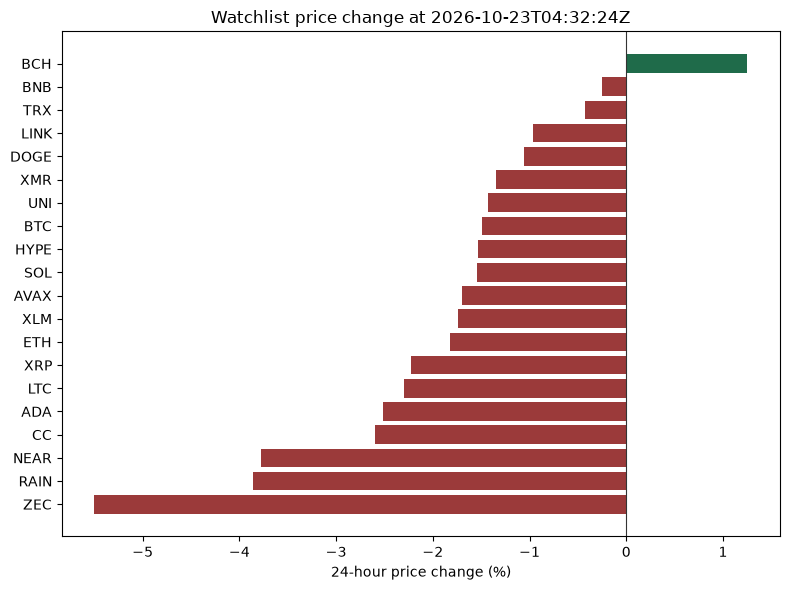

In [2]:
if prices.empty:
    print("No CoinGecko snapshot yet. Run: python -m ai_crypto_signals collect markets")
else:
    panel = prices.sort_values("price_change_percentage_24h")
    colors = ["#9b3a3a" if value < 0 else "#1f6b4a" for value in panel["price_change_percentage_24h"]]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.barh(panel["symbol"], panel["price_change_percentage_24h"], color=colors)
    ax.axvline(0, color="#333333", linewidth=0.8)
    ax.set_xlabel("24-hour price change (%)")
    collected = panel["collected_at"].iloc[0]
    ax.set_title(f"Watchlist price change at {collected}")
    fig.tight_layout()
    plt.show()


## Polymarket

The slice is the 200 crypto-tagged markets Gamma returned with the highest 24-hour volume, among markets the API still marked open. `yes_price` is filled only when the outcomes are Yes and No. Up/Down contracts stay out of that column. Markets whose end time is already past are dropped from the chart and counted in the printout, because a resolved bracket is not a live bet.


Markets in the slice: 200
End time already past at collection: 4
Still open, with Yes/No outcomes: 192


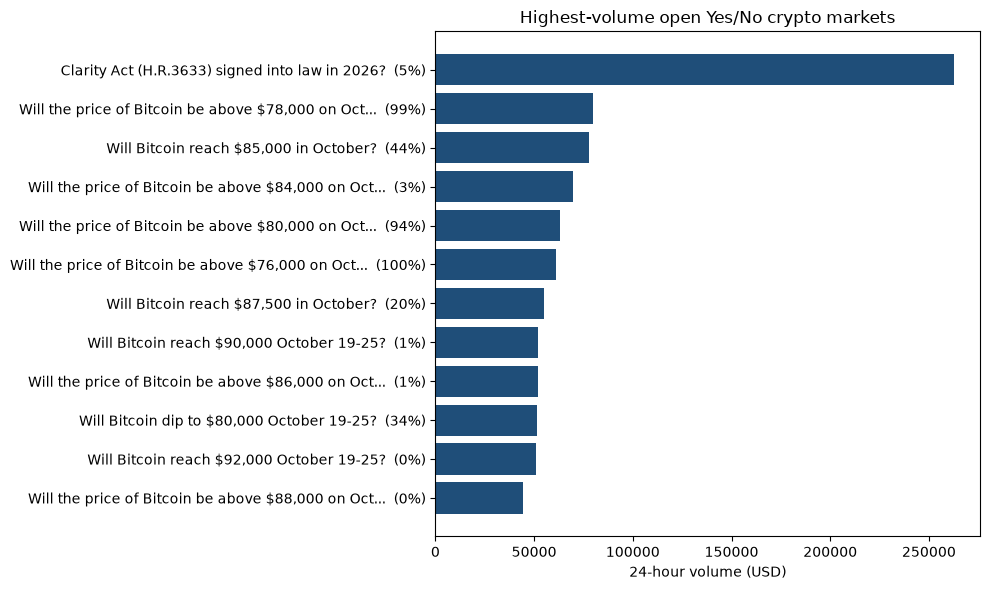

In [3]:
if odds.empty:
    print("No Polymarket snapshot yet.")
else:
    ended = odds["ended"].map(lambda value: str(value).lower() == "true" or value is True)
    live = odds.loc[~ended].copy()
    yes_no = live["outcomes"].fillna("").str.contains("Yes")
    print(f"Markets in the slice: {len(odds)}")
    print(f"End time already past at collection: {int(ended.sum())}")
    print(f"Still open, with Yes/No outcomes: {int(yes_no.sum())}")
    chart = live.loc[yes_no].nlargest(12, "volume_24hr").iloc[::-1]
    if chart.empty:
        print("No open Yes/No markets in this snapshot.")
    else:
        labels = []
        for question, price in zip(chart["question"], chart["yes_price"]):
            short = question if len(question) <= 52 else question[:49] + "..."
            labels.append(f"{short}  ({price:.0%})")
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.barh(labels, chart["volume_24hr"], color="#1f4e79")
        ax.set_xlabel("24-hour volume (USD)")
        ax.set_title("Highest-volume open Yes/No crypto markets")
        fig.tight_layout()
        plt.show()


## What the chat answer ranked

The points are ranks parsed from the manual answers. Each series is one provider on one UTC date. A missing provider means that sitting did not produce an answer. Coins named only as examples stay out of the chart. Sentiment stays `unspecified` when the extractor does not attach a rationale. The lexicon only tags words such as "bullish" or "dump".


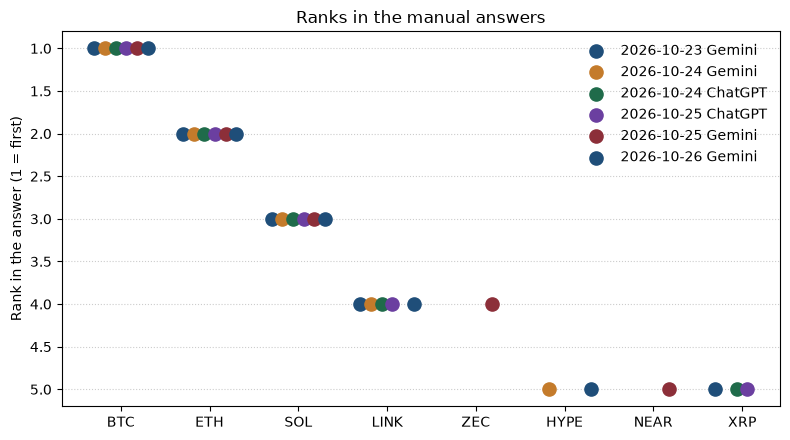

        collected_at provider_label symbol  rank           rationale sentiment_label
2026-10-23T13:09:00Z         Gemini    BTC   1.0                 NaN     unspecified
2026-10-23T13:09:00Z         Gemini    ETH   2.0                 NaN     unspecified
2026-10-23T13:09:00Z         Gemini    SOL   3.0                 NaN     unspecified
2026-10-23T13:09:00Z         Gemini   LINK   4.0                 NaN     unspecified
2026-10-23T13:09:00Z         Gemini    XRP   5.0                 NaN     unspecified
2026-10-23T13:09:00Z         Gemini    ARB   NaN                 NaN     unspecified
2026-10-23T13:09:00Z         Gemini     OP   NaN                 NaN     unspecified
2026-10-24T13:06:00Z         Gemini    BTC   1.0                 NaN     unspecified
2026-10-24T13:06:00Z         Gemini    ETH   2.0                 NaN     unspecified
2026-10-24T13:06:00Z         Gemini    SOL   3.0                 NaN     unspecified
2026-10-24T13:06:00Z         Gemini   LINK   4.0                 

In [4]:
manual = mentions[mentions["source"] == "manual_chat"] if not mentions.empty else mentions
if manual.empty:
    print("No manual mentions yet. Paste a chat answer into data/raw/llm_manual/ and run process.")
else:
    ranked_rows = manual[manual["rank"].notna()].copy()
    ranked_rows["series"] = ranked_rows["collected_at"].str.slice(0, 10) + " " + ranked_rows["provider_label"]
    symbols = list(dict.fromkeys(ranked_rows.sort_values(["rank", "symbol"])["symbol"]))
    series = list(dict.fromkeys(ranked_rows.sort_values("collected_at")["series"]))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    offsets = {label: (index - (len(series) - 1) / 2) * 0.12 for index, label in enumerate(series)}
    colors = ["#1f4e79", "#c47b2b", "#1f6b4a", "#6b3fa0", "#8c2f39"]
    for index, label in enumerate(series):
        subset = ranked_rows[ranked_rows["series"] == label]
        positions = [symbols.index(symbol) + offsets[label] for symbol in subset["symbol"]]
        ax.scatter(positions, subset["rank"], s=90, color=colors[index % len(colors)], label=label, zorder=3)
    ax.set_xticks(range(len(symbols)))
    ax.set_xticklabels(symbols)
    ax.set_ylabel("Rank in the answer (1 = first)")
    ax.invert_yaxis()
    ax.set_title("Ranks in the manual answers")
    ax.legend(frameon=False)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, linestyle=":", color="#cccccc")
    fig.tight_layout()
    plt.show()
    print(manual[["collected_at", "provider_label", "symbol", "rank", "rationale", "sentiment_label"]].to_string(index=False))


## Overlap with the market slice, and the lead-lag screen

The bars count how many of the 200 markets mention a coin the answer ranked. A zero means that coin's name or ticker did not appear in this volume-capped slice. It does not mean Polymarket has no market on that coin.

The agreement table compares providers that produced mentions on the same UTC date. The lead-lag screen stays silent until prices exist on two dates and there are enough coin-snapshot pairs. When it does print a correlation, that number is a description of the sample.


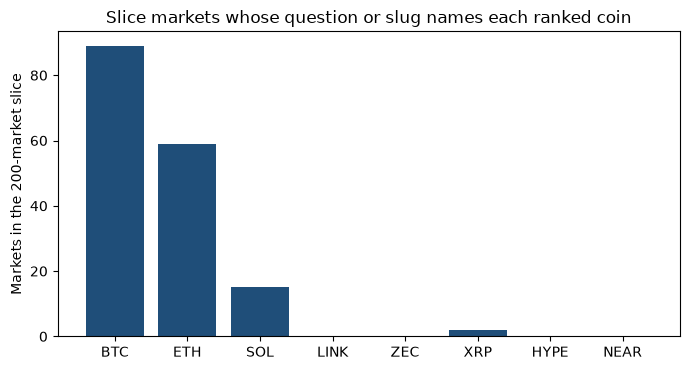

Provider overlap on coins mentioned that UTC date:
      date provider_a provider_b  n_a  n_b  n_overlap  jaccard  n_ranked_overlap  spearman_rank
2026-10-24     google     openai    5    5          4 0.666667                 4            1.0
2026-10-25     google     openai    5    5          3 0.428571                 3            1.0

Lead-lag estimable: False
Price dates: 1
Pairs: 0 (minimum 8)
Lead-lag needs price snapshots on at least two UTC dates. The panel currently has 1.


In [5]:
if manual.empty or odds.empty:
    print("Overlap chart waits on both a mention table and a Polymarket snapshot.")
else:
    ranked_rows = manual[manual["rank"].notna()]
    ranked = list(dict.fromkeys(ranked_rows.sort_values("rank")["symbol"]))
    counts = []
    for symbol in ranked:
        linked = odds["linked_symbols"].fillna("").str.split("|")
        counts.append(int(linked.map(lambda symbols, needle=symbol: needle in symbols).sum()))
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.bar(ranked, counts, color="#1f4e79")
    ax.set_ylabel("Markets in the 200-market slice")
    ax.set_title("Slice markets whose question or slug names each ranked coin")
    fig.tight_layout()
    plt.show()

compared = manual if not manual.empty else mentions
table = agreement_table(compared if not compared.empty else pd.DataFrame())
if table.empty:
    print("No provider pair to compare yet.")
else:
    print("Provider overlap on coins mentioned that UTC date:")
    print(table.to_string(index=False))

screen = lead_lag_screen(prices, mentions)
print()
print(f"Lead-lag estimable: {screen['estimable']}")
print(f"Price dates: {screen['n_price_dates']}")
print(f"Pairs: {screen['n_pairs']} (minimum {screen['min_pairs']})")
print(screen["reason"])
